<a href="https://www.pieriandata.com"><img src="data/Logo.jpg"></a>
*Copyright by Pierian Data Inc.*

# Feature Matching

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [8]:
def display_image(img, cmap='gray'):
    plt.figure(figsize=(12,10))
    plt.imshow(img, cmap=cmap)

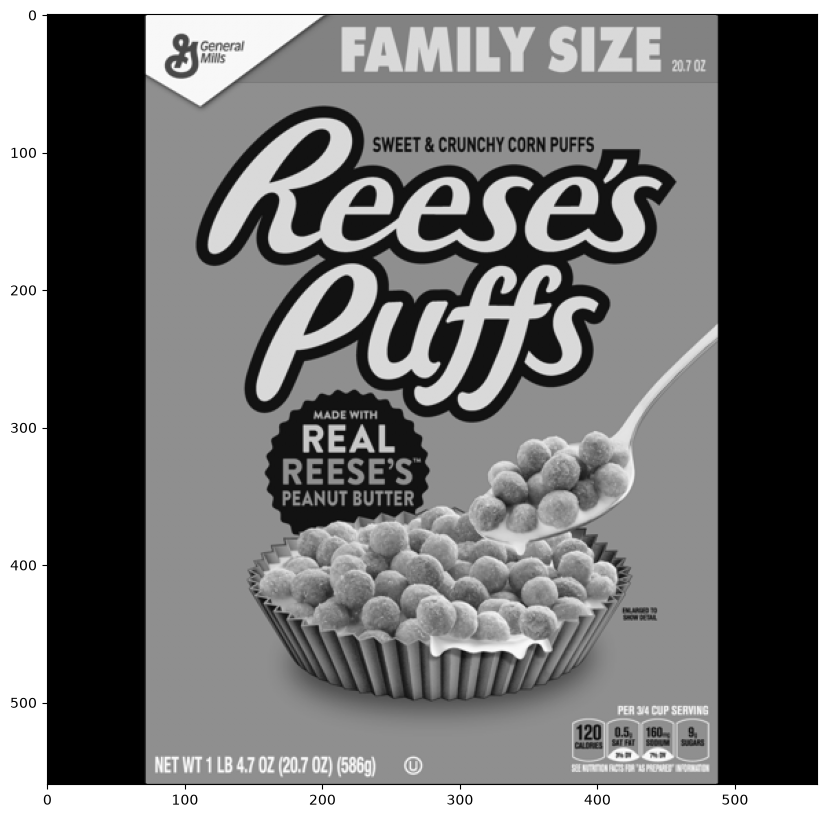

In [9]:
reeses = cv2.imread('data/reeses_puffs.png', 0)
display_image(reeses)

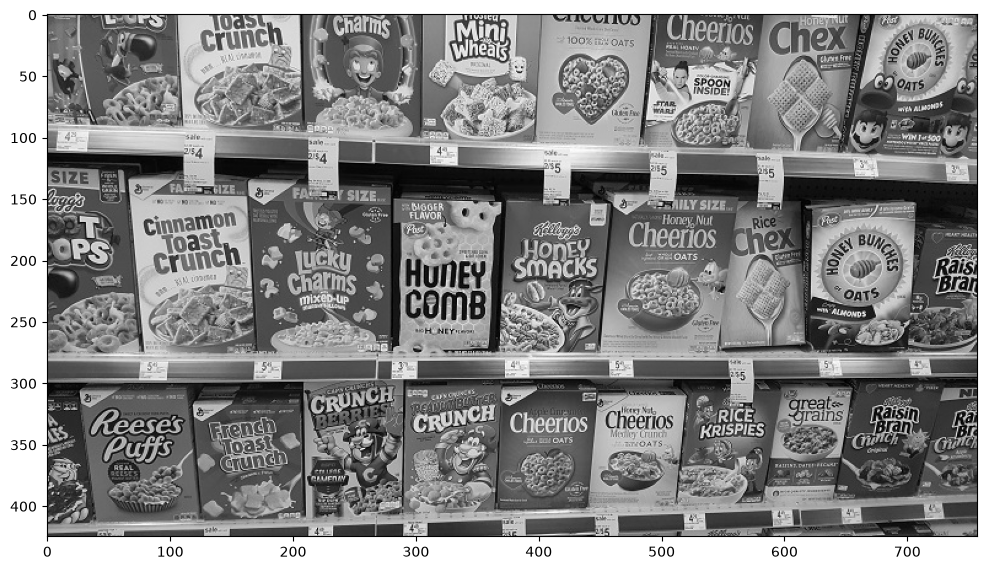

In [10]:
cereals = cv2.imread('data/many_cereals.jpg', 0)
display_image(cereals)

--------
# Brute Force Detection with ORB Descriptors

**`orb.detectAndCompute()`**  

**ORB** = Oriented FAST and Rotated BRIEF

A fast, efficient algorithm that detects keypoints and computes binary descriptors. It is useful for real-time applications and resource-constrained devices.

The function performs two tasks:  
1. **Detect keypoints** — finds distinctive points in the image, such as corners and textured regions.
2. **Compute descriptors** — creates a numerical description of the local image pattern around each keypoint.

It returns two outputs: `kp1` and `des1`.  

`kp1` — Keypoints  
A list of detected keypoint objects. Each keypoint contains information such as its position, size, orientation, and response strength.  

`des1` — Descriptors  
A NumPy array containing the binary descriptors associated with the detected keypoints.  
With standard ORB settings, each descriptor is 32 bytes (256 bits).  

In [46]:
# Creates the ORB feature detector and descriptor extractor
orb = cv2.ORB_create()

# Find the keypoints and descriptors with ORB
kp1, des1 = orb.detectAndCompute(image=reeses, mask=None)
kp2, des2 = orb.detectAndCompute(image=cereals, mask=None)

**`cv2.BFMatcher()`**  
`BFMatcher` stands for Brute-Force Matcher. It compares the descriptor of each keypoint in one image against descriptors in another image to find the most similar features.  
For example, if you have two images of the same object, it can help identify which features correspond to each other.

`cv2.NORM_HAMMING`
This specifies the distance metric used to compare descriptors. ORB produces binary descriptors, so Hamming distance is appropriate.
Example:

![norm_harming](data/norm_harming.png)

Hamming distance counts the number of bit positions that differ. A smaller distance generally means the descriptors are more similar.  

`crossCheck=True`  
This enables mutual best matching. A descriptor in image 1 must select a descriptor in image 2 as its best match, and that descriptor in image 2 must also select the original descriptor as its best match.  
- `crossCheck=True`: keeps only mutual best matches.  
- `crossCheck=False`: allows one-way nearest-neighbor matching, which can return more candidates.  
Cross-checking often removes ambiguous matches, but it does not guarantee that every remaining match is correct.

In [47]:
# Create BFMatcher object
bf = cv2.BFMatcher(normType=cv2.NORM_HAMMING, crossCheck=True)

In [48]:
# Match descriptors
matches = bf.match(des1, des2)
# NOTE: compares the descriptors from two images and finds the best matching pairs of features.

In [49]:
matches[:5]

(< cv2.DMatch 0x7a60f8cd4f90>,
 < cv2.DMatch 0x7a60f8cd5cd0>,
 < cv2.DMatch 0x7a60f4291410>,
 < cv2.DMatch 0x7a60f4291450>,
 < cv2.DMatch 0x7a60f42912b0>)

In [29]:
for match in matches:
    print(match.distance)

71.0
58.0
77.0
67.0
69.0
63.0
56.0
74.0
69.0
66.0
62.0
59.0
62.0
55.0
76.0
63.0
81.0
71.0
75.0
55.0
64.0
59.0
54.0
84.0
70.0
60.0
46.0
69.0
70.0
54.0
53.0
73.0
79.0
70.0
78.0
74.0
54.0
54.0
63.0
77.0
62.0
45.0
64.0
68.0
78.0
63.0
68.0
58.0
65.0
49.0
67.0
70.0
63.0
42.0
58.0
58.0
72.0
61.0
63.0
52.0
67.0
71.0
82.0
52.0
55.0
54.0
73.0
64.0
61.0
66.0
70.0
59.0
76.0
79.0
67.0
75.0
63.0
53.0
68.0
72.0
59.0
72.0
53.0
50.0
62.0
69.0
73.0
51.0
57.0
56.0
70.0
84.0
62.0
74.0
74.0
75.0
50.0
65.0
80.0
65.0
67.0
75.0
79.0
76.0
60.0
57.0
71.0
66.0
60.0
61.0
76.0
57.0
76.0
75.0
81.0
79.0
77.0
69.0
70.0
67.0
64.0
67.0
69.0
68.0
66.0
70.0
74.0
72.0
69.0
84.0
76.0
78.0
75.0
84.0
78.0
83.0
68.0
82.0
82.0


In [30]:
# Sort them in the order of their distance
matches = sorted(matches, key=lambda x: x.distance) 

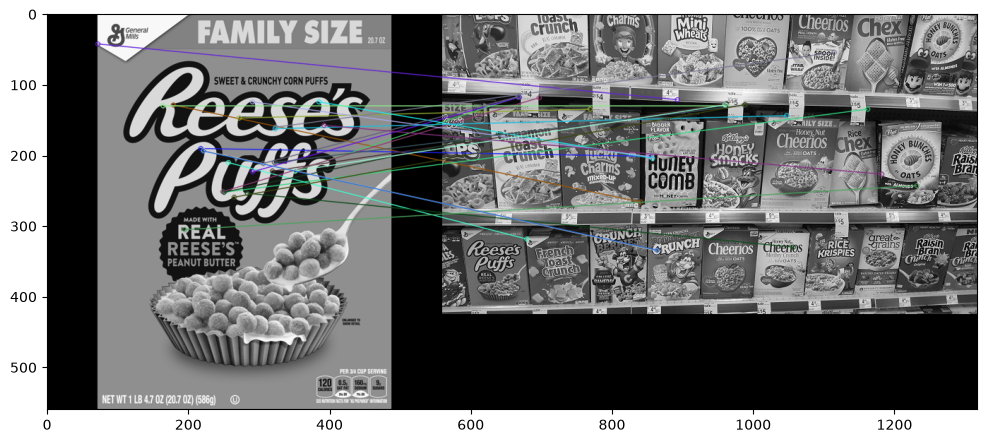

In [35]:
# Draw first 25 matches
reeses_matches = cv2.drawMatches(img1 = reeses, 
                                 keypoints1 = kp1, # keypoints detected in the first image
                                 img2 = cereals, 
                                 keypoints2 = kp2, # keypoints detected in the second image
                                 matches1to2 = matches[:25], # draws only the first 25 matches from the sorted match list
                                 outImg = None, # create a new output image automatically
                                 flags = 2) # cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
display_image(reeses_matches)

# Brute-Force Matching with SIFT Descriptors and Ratio Test

**SIFT** = Scale-Invariant Feature Transform  
An algorithm that detects distinctive keypoints at different scales and computes more detailed descriptors. It is often useful when images differ in size, scale, or viewpoint.

In [53]:
# Create SIFT object
sift = cv2.SIFT_create()

# Find the keypoints and descriptors with SIFT
kp1, des1 = sift.detectAndCompute(image=reeses, mask=None)
kp2, des2 = sift.detectAndCompute(image=cereals, mask=None)

In [54]:
des1

array([[19.,  0.,  0., ...,  1.,  0.,  0.],
       [15.,  0.,  0., ..., 11.,  1.,  0.],
       [21.,  0.,  0., ...,  0., 10., 13.],
       ...,
       [61.,  6.,  0., ...,  0.,  0.,  0.],
       [27.,  0.,  0., ...,  0.,  0.,  0.],
       [48.,  0.,  0., ...,  0.,  1.,  0.]],
      shape=(1501, 128), dtype=float32)

In [55]:
# BFMatcher with default params
bf = cv2.BFMatcher()

# Find the two nearest matching descriptors for each descriptor in the first image.
matches = bf.knnMatch(queryDescriptors = des1, # descriptors from the first image that you want to match
                      trainDescriptors = des2,  # descriptors from the second image to search against
                      k = 2)                   # returns up to two nearest matches for each query descriptor

In [56]:
matches[:5]

((< cv2.DMatch 0x7a60fafafb30>, < cv2.DMatch 0x7a60f8cd5b70>),
 (< cv2.DMatch 0x7a60d0faad70>, < cv2.DMatch 0x7a60d0faacb0>),
 (< cv2.DMatch 0x7a60d0faacf0>, < cv2.DMatch 0x7a60d0faad90>),
 (< cv2.DMatch 0x7a60d0faabd0>, < cv2.DMatch 0x7a60d0faab50>),
 (< cv2.DMatch 0x7a60d0faacd0>, < cv2.DMatch 0x7a60d0faae30>))

In [64]:
# Apply distance ratio
good = []

# Ratio 'match1' < 75% of 'match2'
for match1, match2 in matches:
    #If 'match1' distance is LESS THAN 75% of 'match2' distance
    # then that descriptor is a good match, let's keep it!
    if match1.distance < 0.75 * match2.distance:
        good.append([match1])

len(good)

79

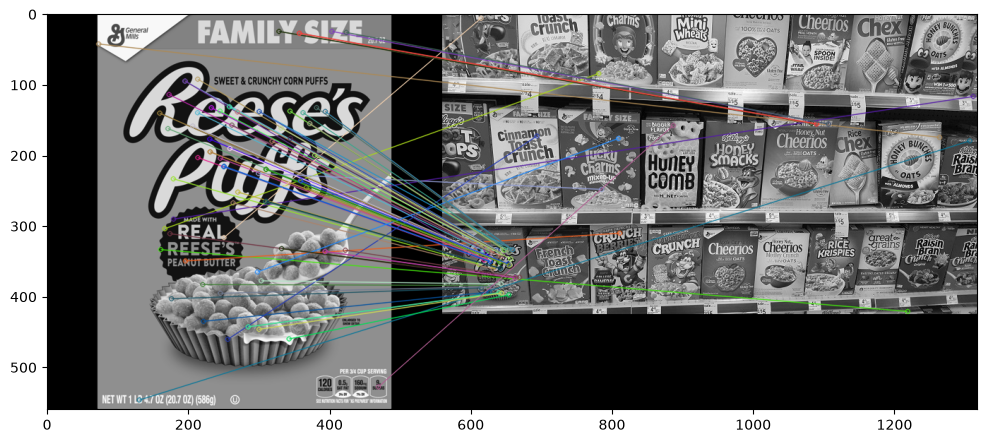

In [66]:
# cv2.drawMatchesKnn expects list of lists as matches.
sift_matches = cv2.drawMatchesKnn(img1 = reeses,      # First input image (Reese's image)                        
                                  keypoints1 = kp1,   # Keypoints detected in the first image
                                  img2 = cereals,     # Second input image (cereal image)
                                  keypoints2 = kp2,   # Keypoints detected in the second image
                                  matches1to2 = good, # Good matches between the two images
                                  outImg = None,      # Output image; None lets OpenCV create it
                                  flags = 2)          # Do not draw keypoints that are not part of matches


display_image(sift_matches)

**Example calculation**  
match1.distance = 221.5716552734375  
match2.distance = 299.5964050292969  
75% of match2.distance = 0.75 * 299.5964050292969 = 0.75 * 299.5964050292969 =224.6973037727052  

`match1.distance < 75% of match2.distance`

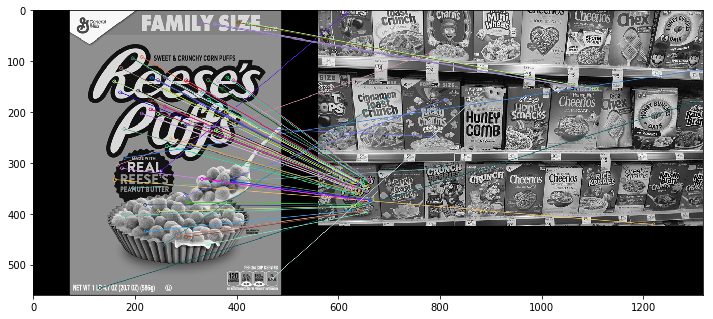

In [10]:
display(sift_matches)

# FLANN based Matcher

**FLANN** stands for Fast Library for Approximate Nearest Neighbors. 

**BFMatcher — Brute-Force Matcher**  
Compares each query descriptor against the candidate descriptors in the other image. It is straightforward and can be accurate, but may take longer for large descriptor sets.

----

**FLANN — Approximate nearest-neighbor search**  
Uses search structures to find likely nearest neighbors without necessarily checking every candidate. It can be faster for large datasets, but the results may not always be the exact nearest neighbors.

In [67]:
# Create SIFT object
sift = cv2.SIFT_create()

# Find the keypoints and descriptors with SIFT
kp1, des1 = sift.detectAndCompute(image=reeses, mask=None)
kp2, des2 = sift.detectAndCompute(image=cereals, mask=None)

# FLANN parameters
FLANN_INDEX_KDTREE = 0
index_params = dict(algorithm = FLANN_INDEX_KDTREE, trees = 5)
search_params = dict(checks = 50)

index_params, search_params

({'algorithm': 0, 'trees': 5}, {'checks': 50})

In [70]:
flann = cv2.FlannBasedMatcher(indexParams = index_params, 
                              searchParams = search_params)

In [71]:
matches = flann.knnMatch(queryDescriptors = des1, 
                         trainDescriptors = des2, 
                         k = 2)
matches[:5]

((< cv2.DMatch 0x7a60faf19e50>, < cv2.DMatch 0x7a61010f90f0>),
 (< cv2.DMatch 0x7a61010f8e70>, < cv2.DMatch 0x7a61010f8f70>),
 (< cv2.DMatch 0x7a61010f9150>, < cv2.DMatch 0x7a61010f9230>),
 (< cv2.DMatch 0x7a61010f8d50>, < cv2.DMatch 0x7a61010f8750>),
 (< cv2.DMatch 0x7a61010f8e10>, < cv2.DMatch 0x7a61010f8cf0>))

In [76]:
# Apply distance ratio
good = []

# Ratio 'match1' < 70% of 'match2'
for match1, match2 in matches:
    #If 'match1' distance is LESS THAN 70% of 'match2' distance
    # then that descriptor is a good match, let's keep it!
    if match1.distance < 0.7 * match2.distance:
        good.append([match1])

len(good)

67

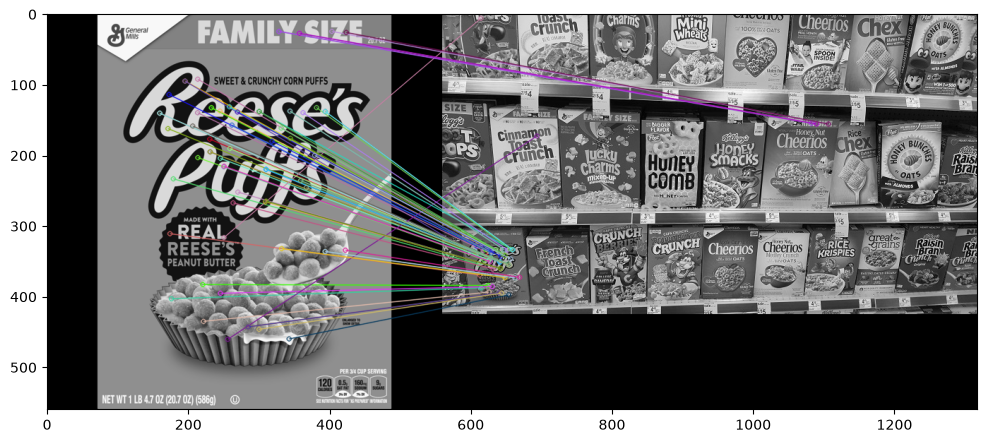

In [77]:
# cv2.drawMatchesKnn expects list of lists as matches.
flann_matches = cv2.drawMatchesKnn(img1 = reeses,      # First input image (Reese's image)                        
                                   keypoints1 = kp1,   # Keypoints detected in the first image
                                   img2 = cereals,     # Second input image (cereal image)
                                   keypoints2 = kp2,   # Keypoints detected in the second image
                                   matches1to2 = good, # Good matches between the two images
                                   outImg = None,      # Output image; None lets OpenCV create it
                                   flags = 2)          # Do not draw keypoints that are not part of matches


display_image(flann_matches)

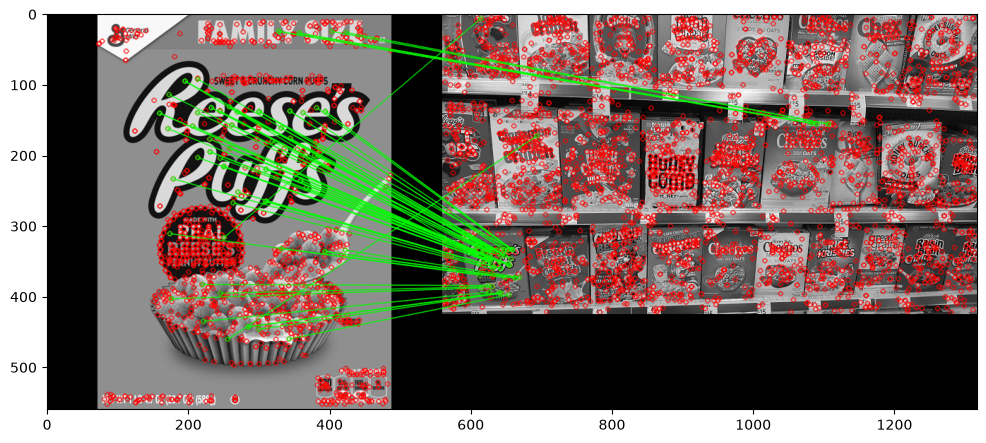

In [86]:
# Create SIFT object
sift = cv2.SIFT_create()

# Find the keypoints and descriptors with SIFT
kp1, des1 = sift.detectAndCompute(image=reeses, mask=None)
kp2, des2 = sift.detectAndCompute(image=cereals, mask=None)

# FLANN parameters
FLANN_INDEX_KDTREE = 0
index_params = dict(algorithm = FLANN_INDEX_KDTREE, trees = 5)
search_params = dict(checks = 50)

flann = cv2.FlannBasedMatcher(indexParams = index_params, 
                              searchParams = search_params)

matches = flann.knnMatch(queryDescriptors = des1, 
                         trainDescriptors = des2, 
                         k = 2)

# Create a mask to draw only matched line
matches_mask = [[0,0] for i in range(len(matches))]

# Ratio 'match1' < 70% of 'match2'
for i, (match1, match2) in enumerate(matches):
    #If 'match1' distance is LESS THAN 70% of 'match2' distance
    # then that descriptor is a good match, let's keep it!
    if match1.distance < 0.7 * match2.distance:
        matches_mask[i] = [1,0]

draw_params = dict(matchColor = (0,255,0),
                   singlePointColor = (255,0,0),
                   matchesMask = matches_mask,
                   flags = 0)

# cv2.drawMatchesKnn expects list of lists as matches.
flann_matches = cv2.drawMatchesKnn(img1 = reeses,      # First input image (Reese's image)                        
                                   keypoints1 = kp1,   # Keypoints detected in the first image
                                   img2 = cereals,     # Second input image (cereal image)
                                   keypoints2 = kp2,   # Keypoints detected in the second image
                                   matches1to2 = matches, # matches between the two images
                                   outImg = None,      # Output image; None lets OpenCV create it
                                   **draw_params)

display_image(flann_matches)